# A Matlab Toolbox for Global Sensitivity Analysis: the HyMod Rainfall-Runoff Model of the Leaf River Catchment

__Francesca Pianosi__, Department of Civil Engineering, University of Bristol, Bristol, UK

__Fanny Sarrazin__, Department of Civil Engineering, University of Bristol, Bristol, UK

__Thorsten Wagener__, Department of Civil Engineering, University of Bristol, Bristol, UK

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The notebook runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes one to two minutes.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import qmc
import active_subspaces as ac
import hymod_model as hm

SEED = 2015                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
names = list(hm.NAMES)            # Sm, beta, alfa, Rs, Rf (the paper's names)
labels = names

### Summary

Pianosi et al. [[1]](https://doi.org/10.1016/j.envsoft.2015.04.009) illustrate their SAFE toolbox for global sensitivity analysis on HyMod, a five-parameter daily rainfall-runoff model, with the Nash-Sutcliffe efficiency (NSE) of simulated against observed Leaf River flow as the output. From 2000 Monte Carlo samples with exact (almost-everywhere) gradients, in the setting of SAFE-matlab's `workflow_eet_hymod.m` (the script excerpted in the paper's Fig. 4: the first 365 days of the record, a 30-day warm-up, all stores empty at day 1), the NSE has a two-dimensional active subspace on the paper's ranges, because the 2.1 % of samples with a soil store below 10 mm ($S_m \to 0$, where the store degenerates) carry 52.1 % of the gradient mass, and with $S_m \ge 10$ mm a one-dimensional active subspace ($\lambda_1/\lambda_2 = 12.81$) along a combination of the quick-flow coefficient $R_f$ and the split alfa, consistent with the paper's Elementary Effects ranking ($R_f$ > alfa > the rest); the peak simulated flow has a one-dimensional active subspace along $R_f$ and alfa ($\lambda_1/\lambda_2 = 18.19$, leave-one-out $R^2 = 0.952$ for a cubic in the active variable), while the mean simulated flow is not well summarized by one or two active variables. These eigenvalue ratios and the full-range $n = 2$ are specific to that first year started from empty stores (dropping the warm-up changes little): in a robustness check with a one-year spin-up and three other water years, the $R_f$–alfa direction persists for the NSE on $S_m \ge 10$ mm and, except in 1959, for the peak flow, but the NSE's $\lambda_1/\lambda_2$ on $S_m \ge 10$ mm falls to 3.26–5.62, the full-range NSE becomes one-dimensional along $S_m$ in the three other years, and the peak flow's $\lambda_1/\lambda_2$ ranges from 2.02 to 17.06.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs, normalized to $[-1,1]^m$ and with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and little along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a function of $\mathbf y$ can stand in for $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess the estimate with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

Pianosi et al. [[1]](https://doi.org/10.1016/j.envsoft.2015.04.009) introduce the SAFE toolbox for global sensitivity analysis and illustrate it (Figs. 3 and 4, pp. 83–84) on HyMod, a five-parameter conceptual rainfall-runoff model (Boyle 2001; Wagener et al. [[2]](https://doi.org/10.5194/hess-5-13-2001)). The output is the Nash-Sutcliffe efficiency (NSE; Nash and Sutcliffe [[7]](https://doi.org/10.1016/0022-1694(70)90255-6)) of simulated against observed daily flow. The paper's text names neither the catchment nor the forcing period, and its Fig. 4 is an excerpt of a version of SAFE-matlab's `workflow_eet_hymod.m` [[9]](https://github.com/SAFEtoolbox/SAFE-matlab) ("prepared by Pianosi and Sarrazin, 2014"): the excerpt's `xmin`/`xmax`, `X_labels`, `myfun = 'hymod_nse'`, `r = 100`, `'lhs'`/`'radial'` and `Nboot = 100` lines are all in the current script. The current script's Step 2 (not shown in Fig. 4) sets the forcing, and we use the same: the Leaf River catchment (Mississippi, USA; data of Sorooshian et al. [[3]](https://doi.org/10.1029/WR019i001p00251)), the first 365 days of `LeafCatch.txt` (`LeafCatch(1:365,:)`), a 30-day warm-up (`warmup = 30`), and stores empty at day 1 (`hymod_sim.m`). SAFE-python's `workflow_eet_hymod.py` uses the same 365 rows and warm-up (its comment "2-year simulation" on that line is stale). Two caveats: the GitHub history of SAFE-matlab starts with an upload on 2022-11-01 (we read commit dc157e1), so the 2015 release is not available; and the Fig. 4 excerpt differs from the current script in Step 4, `Y = model_evaluation(myfun,X)` against `model_execution(myfun,X,rain,evap,flow,warmup)`, with no `warmup = 30` line after `myfun`. So the 2015 run may have used a different warm-up (or none); the robustness section below includes a no-warm-up case. See `DATA.md`.

The model has a soil-moisture store $s$ of capacity $S_m$, a slow (groundwater) linear reservoir $L$ and a cascade of three quick linear reservoirs $f_1, f_2, f_3$, all empty at the start. On day $t$, with rainfall $r_t$ and potential evapotranspiration $e_t$ (mm/day), and $u = s/S_m$:

$$
\begin{aligned}
s^{+} &= \min\{\,s + r_t (1-u)^{\beta},\; S_m\}, &\quad P_e &= s + r_t - s^{+} &&\text{(excess rainfall, including overflow)}\\
s' &= \max\{\,s^{+} - \min(u, 1)\, e_t,\; 0\}, & && &&\text{(evapotranspiration)}\\
Q_s &= R_s L, & L' &= L + (1-\text{alfa})\,P_e - Q_s &&\text{(slow flow)}\\
Q_f &= R_f f_3, & f_1' &= f_1 + \text{alfa}\,P_e - R_f f_1,\;\; f_k' = f_k + R_f (f_{k-1} - f_k),\ k = 2, 3 &&\text{(quick flow)}
\end{aligned}
$$

and the simulated flow is $Q_t = Q_s + Q_f$ (mm/day). The fraction of rain that becomes excess, $1-(1-u)^\beta$, grows with the soil-moisture fraction $u$. These are the update rules of SAFE's `hymod_sim` (including the floor of $S_m$ at machine epsilon, $\min(|s/S_m|, 1)$ from the start-of-day store, the soil clip before evaporation, and outflows from start-of-day storages). They were taken from reading SAFE's code, since no published description gives them, and written fresh in numpy in `hymod_model.py` (SAFE is GPL-3.0; no code or comments are copied); `DATA.md` shows that the two agree to rounding.

**Quantities of interest**, over days 31–365 (335 days):

- $\mathrm{NSE} = 1 - \sum_t (Q_t - Q^{\mathrm{obs}}_t)^2 / \sum_t (Q^{\mathrm{obs}}_t - \bar Q^{\mathrm{obs}})^2$, dimensionless, at most 1 (the paper's output, SAFE `hymod_nse`);
- $Q_{\max} = \max_t Q_t$, the peak simulated flow in mm/day (SAFE `hymod_max`, used in its PAWN workflow);
- $\bar Q = \frac{1}{335}\sum_t Q_t$, the mean simulated flow in mm/day (added here as a flow statistic that is not a misfit).

**Inputs.** The paper's Fig. 4 workflow script gives five independent uniform inputs, "Parameter ranges (from literature)"; SAFE's Python workflow attributes them to Kollat et al. [[4]](https://doi.org/10.1029/2011WR011534). The paper gives no units; those below are SAFE's.

In [2]:
desc = {'Sm': 'maximum soil moisture storage', 'beta': 'exponent of the soil-moisture (excess) curve',
        'alfa': 'fraction of excess rainfall to the quick reservoirs', 'Rs': 'slow reservoir outflow coefficient',
        'Rf': 'quick reservoir outflow coefficient'}
print(f"{'input':6s} {'units':7s} {'lower':>6s} {'upper':>6s}  description (ranges: paper Fig. 4, p. 84)")
for j, n in enumerate(names):
    print(f'{n:6s} {hm.UNITS[j]:7s} {hm.LOWER[j]:6g} {hm.UPPER[j]:6g}  {desc[n]}')
rain, pet, flow = hm.load_forcing()
w = slice(hm.WARMUP, None)
print(f'\nforcing: {len(rain)} days; rain {rain.sum():.0f} mm, potential ET {pet.sum():.0f} mm, observed flow '
      f'{flow.sum():.0f} mm; over days {hm.WARMUP + 1}-365: mean observed flow {flow[w].mean():.3f} mm/day, '
      f'peak {flow[w].max():.2f} mm/day; mean potential ET {pet.mean():.2f} mm/day')

input  units    lower  upper  description (ranges: paper Fig. 4, p. 84)
Sm     mm           0    400  maximum soil moisture storage
beta   -            0      2  exponent of the soil-moisture (excess) curve
alfa   -            0      1  fraction of excess rainfall to the quick reservoirs
Rs     1/day        0    0.1  slow reservoir outflow coefficient
Rf     1/day      0.1      1  quick reservoir outflow coefficient

forcing: 365 days; rain 2057 mm, potential ET 985 mm, observed flow 956 mm; over days 31-365: mean observed flow 2.818 mm/day, peak 26.86 mm/day; mean potential ET 2.70 mm/day


NSE of the three runs: 0.38, 0.25, 0.34


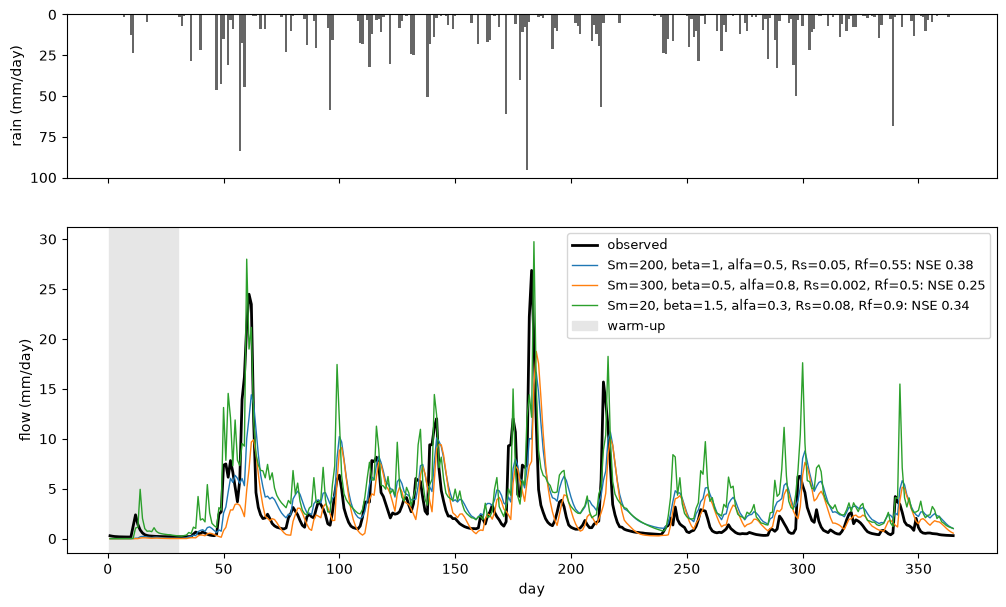

In [3]:
P3 = np.array([hm.NOMINAL, [300, 0.5, 0.8, 0.002, 0.5], [20, 1.5, 0.3, 0.08, 0.9]])
Q3 = hm.simulate(P3, rain, pet)
f3 = hm.qoi(P3)
days = np.arange(1, len(rain) + 1)
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [1, 2]})
ax0.bar(days, rain, color='0.4', width=1.0)
ax0.set_ylabel('rain (mm/day)')
ax0.invert_yaxis()
ax1.plot(days, flow, 'k', lw=2, label='observed')
for p, q, v in zip(P3, Q3, f3):
    ax1.plot(days, q, lw=1, label=f'Sm={p[0]:g}, beta={p[1]:g}, alfa={p[2]:g}, Rs={p[3]:g}, Rf={p[4]:g}: NSE {v[0]:.2f}')
ax1.axvspan(0.5, hm.WARMUP + 0.5, color='0.9', label='warm-up')
ax1.set_xlabel('day')
ax1.set_ylabel('flow (mm/day)')
ax1.legend(fontsize=9)
plt.close(fig)
print('NSE of the three runs:', ', '.join(f'{v:.2f}' for v in f3[:, 0]))
fig

The first 365 days of the forcing hold 2057 mm of rain, 985 mm of potential evapotranspiration and 956 mm of observed flow. The figure shows the observed hydrograph and three simulations: the range midpoints, a slow-draining setting ($R_s = 0.002$/day) and a small, flashy store ($S_m = 20$ mm, $R_f = 0.9$/day). Their NSE values (0.38, 0.25, 0.34) show that no point of the box fits well; the best of the 2000 samples below reaches 0.669.

### Load data

`generate_data.py` drew $M = 2000$ independent uniform samples of the five parameters (plain Monte Carlo, `numpy.random.default_rng(2015)`) and wrote the physical inputs, the three QoIs, and their gradients with respect to the physical parameters (see `DATA.md`).

In [4]:
X = np.loadtxt('inputs.csv', delimiter=',')                         # (M, 5) Sm, beta, alfa, Rs, Rf
f = np.loadtxt('outputs.csv', delimiter=',')                        # (M, 3) NSE, Qmean, Qmax
G = np.loadtxt('gradients.csv', delimiter=',').reshape(-1, 3, 5)    # (M, 3, 5) d(QoI)/d(parameter), physical
print(f'inputs {X.shape}, outputs {f.shape}, gradients {G.shape}; QoIs {hm.QOI_NAMES}')

inputs (2000, 5), outputs (2000, 3), gradients (2000, 3, 5); QoIs ('NSE', 'Qmean', 'Qmax')


**Gradients.** HyMod's clips (the store overflowing at $S_m$ or emptying at 0) make each QoI continuous and piecewise smooth in the parameters, with kinks where a clip switches on some day. `hymod_model.qoi_and_grad` carries exact derivatives of each smooth piece through the daily recursion (forward mode); they are the gradient almost everywhere. The next cell checks the files against the model and the gradients against central differences with two steps, $h = 10^{-6}$ and $h = 10^{-3}$ in normalized units (a fraction of the half-range of each input), on 200 samples. It also counts the samples near the edges of the ranges where the model degenerates.

In [5]:
half = (hm.UPPER - hm.LOWER) / 2
rows = np.arange(200)
fr, Gr = hm.qoi_and_grad(X[rows])
print(f'model vs outputs.csv (200 rows): max relative difference {np.max(np.abs(fr - f[rows]) / np.abs(f[rows])):.1e}')
Gx = G[rows] * half                                              # gradients w.r.t. normalized inputs
for h in (1e-6, 1e-3):
    Gfd = np.empty_like(Gx)
    for j in range(5):
        dp = np.zeros(5)
        dp[j] = h * half[j]
        Gfd[:, :, j] = (hm.qoi(X[rows] + dp) - hm.qoi(X[rows] - dp)) / (2 * h)
    rel = np.linalg.norm(Gfd - Gx, axis=2) / np.linalg.norm(Gx, axis=2)
    print(f'central differences, h = {h:g}: relative error of the gradient vector, median / max: '
          + '; '.join(f'{q} {np.median(rel[:, k]):.1e} / {rel[:, k].max():.1e} ({(rel[:, k] > 1e-3).sum()} rows > 1e-3)'
                      for k, q in enumerate(hm.QOI_NAMES)))
print(f'\nSm < 10 mm: {(X[:, 0] < 10).sum()} samples ({(X[:, 0] < 10).mean():.1%}); Sm < 1 mm: {(X[:, 0] < 1).sum()}; '
      f'Rs < 0.001 /day (slow-store time constant > 1000 days): {(X[:, 3] < 1e-3).sum()}')
print(f'NSE: range [{f[:, 0].min():.2f}, {f[:, 0].max():.3f}], median {np.median(f[:, 0]):.3f}, '
      f'{(f[:, 0] > 0.5).sum()} samples with NSE > 0.5; Qmean range [{f[:, 1].min():.2f}, {f[:, 1].max():.2f}] mm/day; '
      f'Qmax range [{f[:, 2].min():.2f}, {f[:, 2].max():.1f}] mm/day')

model vs outputs.csv (200 rows): max relative difference 5.1e-16


central differences, h = 1e-06: relative error of the gradient vector, median / max: NSE 3.1e-10 / 7.0e-05 (0 rows > 1e-3); Qmean 6.7e-10 / 5.5e-05 (0 rows > 1e-3); Qmax 2.3e-10 / 3.5e-05 (0 rows > 1e-3)


central differences, h = 0.001: relative error of the gradient vector, median / max: NSE 2.5e-06 / 1.4e-01 (18 rows > 1e-3); Qmean 2.2e-06 / 1.9e-02 (10 rows > 1e-3); Qmax 1.1e-06 / 1.7e-01 (7 rows > 1e-3)

Sm < 10 mm: 43 samples (2.1%); Sm < 1 mm: 7; Rs < 0.001 /day (slow-store time constant > 1000 days): 12
NSE: range [-4.82, 0.669], median 0.165, 67 samples with NSE > 0.5; Qmean range [0.26, 5.95] mm/day; Qmax range [1.05, 92.8] mm/day


The files match the model to $5.1\times10^{-16}$. With $h = 10^{-6}$ the central differences agree with the forward-mode gradients to a median relative error of $2$–$7\times10^{-10}$ and at most $7.0\times10^{-5}$ (NSE). With $h = 10^{-3}$ the median is still $1$–$3\times10^{-6}$, but 18 (NSE), 10 (mean flow) and 7 (peak flow) of the 200 samples differ by more than $10^{-3}$, up to 0.14 (NSE) and 0.17 (peak flow): a kink lies inside the stencil. So finite differences with a moderate step would be unreliable at a few percent of the samples; the forward-mode gradients are not.

All samples lie inside the paper's ranges and are valid model inputs; none is outside physical meaning. Two edges of the box are degenerate, though: 43 samples (2.1 %) have $S_m < 10$ mm (7 below 1 mm), a soil store that holds almost nothing, and 12 have $R_s < 0.001$/day, a slow store that hardly drains within the year. We keep them in the main analysis and measure their effect below. The NSE ranges from $-4.82$ to 0.669 (median 0.165; 67 samples above 0.5).

### Estimate the subspace

The model is cheap and we have exact (almost-everywhere) gradients, so we use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates. The input space is `ac.Uniform` on the paper's ranges; we pass physical inputs and physical gradients, and the library scales each gradient component by its half-range once. We use 500 bootstrap replicates, the library's default dimension rule (the largest linear eigenvalue gap, $\lambda_k - \lambda_{k+1}$), and orient each $\mathbf w_k$ so that the QoI increases along it.

In [6]:
space = ac.Uniform(hm.LOWER, hm.UPPER, names=names)


def estimate(space, X, f, G):
    sub = ac.active_subspace(space=space, X=X, f=f, grads=G, estimator='as', nboot=500, rng=SEED)
    return ac.orient(sub, by='covariance', X=X, f=f, columns=2)


def report(subs, title):
    print(title)
    print(f"{'QoI':6s} {'n':>2s}  {'eigenvalues':44s} {'l1/l2':>6s} {'l2/l3':>6s}  w1 ({', '.join(names)})")
    for q, s in subs.items():
        lam = s.eigenvalues
        print(f'{q:6s} {s.n:2d}  {np.array2string(lam, precision=3, max_line_width=200):44s} {lam[0] / lam[1]:6.2f} '
              f'{lam[1] / lam[2]:6.2f}  {np.array2string(s.W[:, 0], precision=3, suppress_small=True)}')


subs = {q: estimate(space, X, f[:, k], G[:, k]) for k, q in enumerate(hm.QOI_NAMES)}
report(subs, 'Full ranges of the paper (M = 2000)')

Full ranges of the paper (M = 2000)
QoI     n  eigenvalues                                   l1/l2  l2/l3  w1 (Sm, beta, alfa, Rs, Rf)
NSE     2  [4.773 2.659 0.17  0.096 0.085]                1.79  15.62  [ 0.86   0.006 -0.237 -0.01  -0.451]
Qmean   1  [1.972e+01 9.978e+00 3.873e-01 3.520e-02 1.098e-02]   1.98  25.76  [-0.996  0.017  0.015  0.084  0.002]
Qmax    1  [977.307  53.728  28.963  22.461  16.548]     18.19   1.86  [-0.072 -0.035  0.452  0.055  0.887]


### Results: NSE on the paper's ranges

**Eigenvalues.** The figure shows the eigenvalues of $\hat{\mathbf C}$ for the NSE with a 95 % bootstrap band.

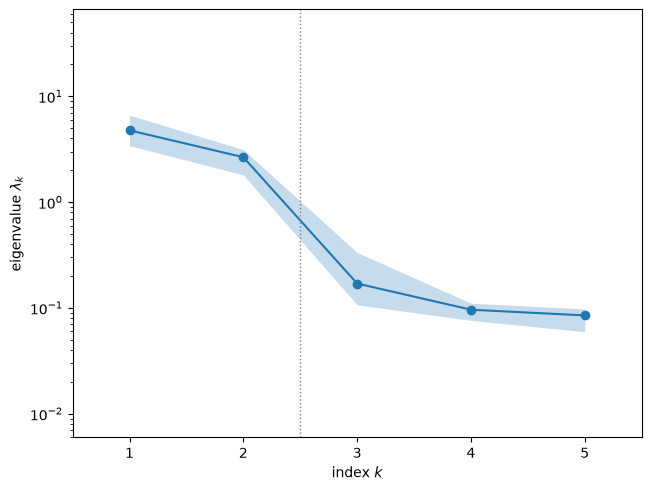

In [7]:
sub = subs['NSE']
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
fig

On the full ranges the gap rule picks $n = 2$ for the NSE: $\lambda_1 = 4.773$, $\lambda_2 = 2.659$, $\lambda_3 = 0.170$, so $\lambda_1/\lambda_2 = 1.79$ and $\lambda_2/\lambda_3 = 15.62$. There is no single dominant direction, but there is a clear two-dimensional subspace. The peak flow ($n = 1$, $\lambda_1/\lambda_2 = 18.19$) and the mean flow ($n = 1$ by the linear gap rule, although $\lambda_1/\lambda_2 = 1.98$ and $\lambda_2/\lambda_3 = 25.76$) are in the table above.

bootstrap mean subspace distance, k = 1..4: [0.162 0.015 0.276 0.449]


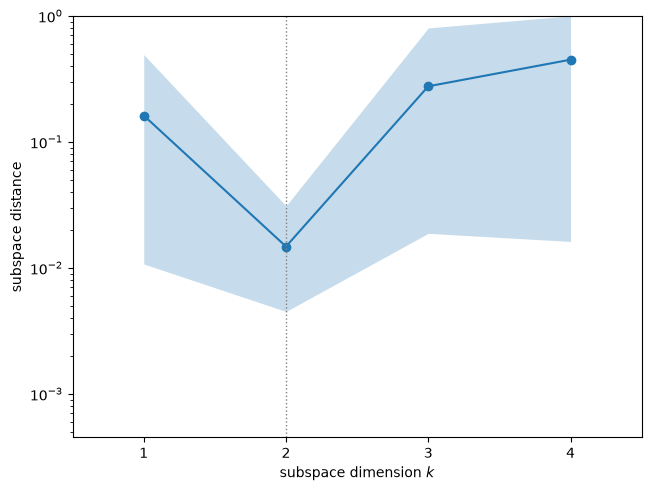

In [8]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..4:', np.array2string(sub.bootstrap_distances.mean(axis=0), precision=3))
fig

The bootstrap mean subspace distance is 0.162 for $k = 1$ and 0.015 for $k = 2$: the first eigenvector alone is uncertain, because $\lambda_1$ and $\lambda_2$ are close, but the two-dimensional subspace is well determined.

w1: Sm +0.860, beta +0.006, alfa -0.237, Rs -0.010, Rf -0.451
w2: Sm -0.509, beta +0.014, alfa -0.344, Rs -0.011, Rf -0.789


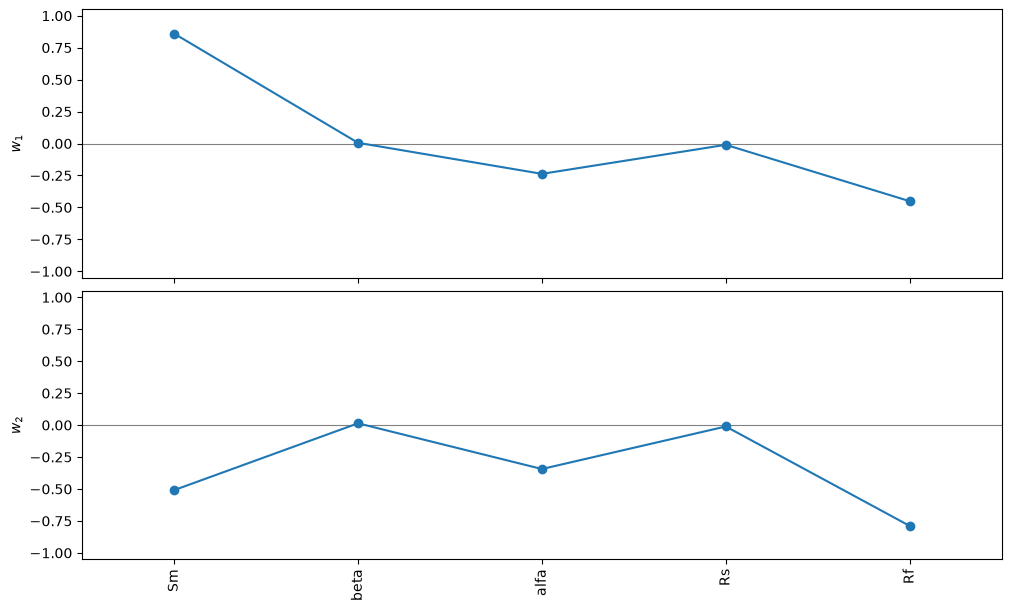

In [9]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(10, 6))
plt.close(fig)
print('w1:', ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, sub.W[:, 0])))
print('w2:', ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, sub.W[:, 1])))
fig

$\mathbf w_1$ is mostly $S_m$ (+0.860), with $R_f$ ($-0.451$) and alfa ($-0.237$); $\mathbf w_2$ is mostly $R_f$ ($-0.789$), with $S_m$ ($-0.509$) and alfa ($-0.344$). beta and $R_s$ have weights of at most 0.014 in magnitude in both. So the two-dimensional subspace is spanned by $S_m$ and a combination of $R_f$ and alfa, and beta and $R_s$ barely affect the NSE.

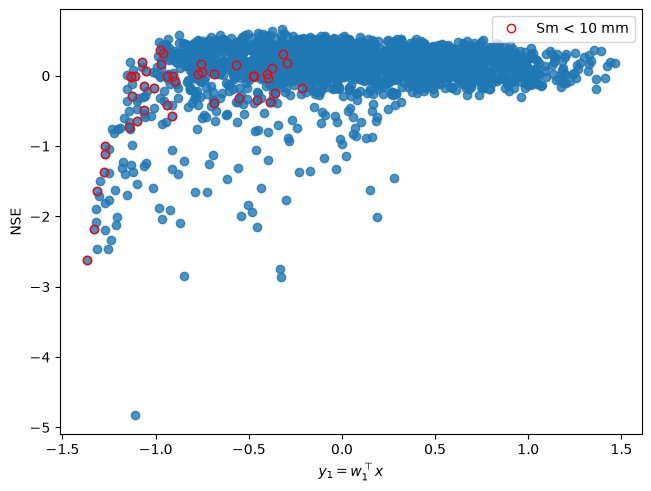

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f[:, 0], dims=1, qoi_label='NSE')
small = X[:, 0] < 10
y1 = space.to_normalized(X) @ sub.W[:, 0]
ax.plot(y1[small], f[small, 0], 'o', mfc='none', mec='r', label='Sm < 10 mm')
ax.legend()
plt.close(fig)
fig

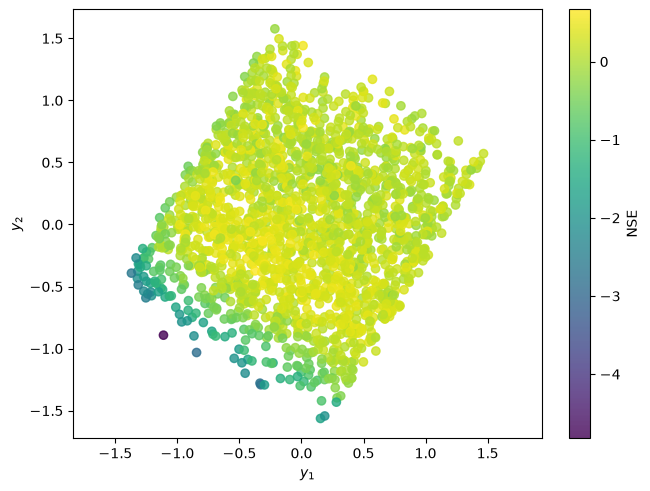

In [11]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f[:, 0], dims=2, qoi_label='NSE')
plt.close(fig)
fig

In the one-dimensional summary plot the NSE rises steeply at the left end and then forms a plateau with a wide spread; most of the 43 samples with $S_m < 10$ mm (red circles) are at the left end. In the two-dimensional plot the low NSE values sit along one edge of the projected domain (small $y_1$ and small $y_2$), and the NSE is nearly flat over the rest. One active variable cannot follow both the $S_m$ edge and the $R_f$–alfa trend.

### Where the gradient mass comes from: small $S_m$

The range of $S_m$ starts at 0, where the soil store vanishes: all rain becomes runoff and nothing evaporates. Near that edge the QoIs change fast with $S_m$. The next cell measures how much of $\mathrm{tr}\,\hat{\mathbf C}$ comes from samples with small $S_m$, and how the eigenvalues and $\mathbf w_1$ change when the lower end of $S_m$ is raised (the samples below the new lower end are dropped and the input space is shrunk to match, so the remaining samples are still uniform on the new box).

In [12]:
bins = [0, 1, 5, 10, 20, 50, 100, 200, 400]
for k, q in enumerate(hm.QOI_NAMES):
    g2 = np.sum((G[:, k] * half) ** 2, axis=1)        # |normalized gradient|^2
    print(f'{q}: share of tr(C) from Sm < 10 mm ({(X[:, 0] < 10).sum()} samples): {g2[X[:, 0] < 10].sum() / g2.sum():.1%}; '
          f'mean |df/dx_Sm| by Sm bin {bins}: '
          + ' '.join(f'{np.abs(G[(X[:, 0] >= a) & (X[:, 0] < b), k, 0] * half[0]).mean():.2f}' for a, b in zip(bins[:-1], bins[1:])))

print(f"\n{'QoI':6s} {'Sm >=':>5s} {'M':>5s} {'l1/l2':>7s} {'l2/l3':>6s}  w1 ({', '.join(names)})")
for k, q in enumerate(hm.QOI_NAMES):
    for lo in (0, 5, 10, 20, 50):
        keep = X[:, 0] >= lo
        sp = ac.Uniform(np.r_[lo, hm.LOWER[1:]], hm.UPPER)
        s = ac.orient(ac.active_subspace(space=sp, X=X[keep], f=f[keep, k], grads=G[keep, k]),
                      by='covariance', X=X[keep], f=f[keep, k], columns=1)
        lam = s.eigenvalues
        print(f'{q:6s} {lo:5d} {keep.sum():5d} {lam[0] / lam[1]:7.2f} {lam[1] / lam[2]:6.2f}  '
              f'{np.array2string(s.W[:, 0], precision=3, suppress_small=True)}')

NSE: share of tr(C) from Sm < 10 mm (43 samples): 52.1%; mean |df/dx_Sm| by Sm bin [0, 1, 5, 10, 20, 50, 100, 200, 400]: 25.21 12.64 4.06 2.08 0.79 0.24 0.10 0.07
Qmean: share of tr(C) from Sm < 10 mm (43 samples): 62.5%; mean |df/dx_Sm| by Sm bin [0, 1, 5, 10, 20, 50, 100, 200, 400]: 54.49 29.18 10.44 4.76 1.60 0.68 0.41 0.36
Qmax: share of tr(C) from Sm < 10 mm (43 samples): 4.5%; mean |df/dx_Sm| by Sm bin [0, 1, 5, 10, 20, 50, 100, 200, 400]: 58.91 28.08 7.43 3.99 3.17 3.87 2.21 0.73

QoI    Sm >=     M   l1/l2  l2/l3  w1 (Sm, beta, alfa, Rs, Rf)
NSE        0  2000    1.79  15.62  [ 0.86   0.006 -0.237 -0.01  -0.451]
NSE        5  1979    7.34   2.66  [ 0.224  0.014 -0.416 -0.014 -0.881]
NSE       10  1957   12.81   1.50  [ 0.177  0.015 -0.416 -0.015 -0.892]
NSE       20  1908   17.81   1.47  [ 0.126  0.015 -0.414 -0.013 -0.901]
NSE       50  1746   15.45   1.87  [ 0.067  0.015 -0.41  -0.014 -0.909]
Qmean      0  2000    1.98  25.76  [-0.996  0.017  0.015  0.084  0.002]


Qmean      5  1979    4.23   6.72  [-0.07   0.037  0.092  0.993  0.003]
Qmean     10  1957    8.67   3.83  [-0.049  0.037  0.092  0.994  0.003]
Qmean     20  1908   14.40   4.32  [-0.037  0.039  0.092  0.994  0.003]
Qmean     50  1746   17.17  15.14  [-0.029  0.04   0.092  0.994  0.004]
Qmax       0  2000   18.19   1.86  [-0.072 -0.035  0.452  0.055  0.887]
Qmax       5  1979   18.44   2.02  [-0.061 -0.036  0.452  0.055  0.888]
Qmax      10  1957   18.56   1.98  [-0.058 -0.036  0.451  0.055  0.888]
Qmax      20  1908   18.53   1.93  [-0.056 -0.037  0.451  0.054  0.888]
Qmax      50  1746   18.01   1.80  [-0.047 -0.041  0.453  0.055  0.888]


The samples with $S_m < 10$ mm are 2.1 % of the design but carry 52.1 % of $\mathrm{tr}\,\hat{\mathbf C}$ for the NSE and 62.5 % for the mean flow (4.5 % for the peak flow). For the NSE the mean $|\partial f/\partial x_{S_m}|$ falls from 25.21 for $S_m < 1$ mm to 0.07 for $S_m > 200$ mm. Raising the lower end of $S_m$ to 5 mm turns the NSE's $\mathbf w_1$ from mostly $S_m$ (+0.86) to mostly $R_f$ ($-0.881$, alfa $-0.416$, $S_m$ +0.224) and raises $\lambda_1/\lambda_2$ from 1.79 to 7.34; from 10 mm on, $\mathbf w_1$ is stable ($R_f$ $-0.892$ to $-0.909$, alfa $-0.416$ to $-0.410$) and $\lambda_1/\lambda_2$ is 12.81–17.81. The mean flow behaves the same way ($\mathbf w_1$ switches from $S_m$ to $R_s$, 0.993–0.994). The peak flow does not depend on the lower end ($\lambda_1/\lambda_2$ = 18.01–18.56, $R_f$ 0.887–0.888).

We therefore add a second analysis with $S_m \in [10, 400]$ mm: a store of 10 mm holds less than four days of the year's mean potential evapotranspiration (2.70 mm/day). The rule is a stated choice, not a correction: the paper's study includes the small values of $S_m$, and the full-range results above are the paper's study.

In [13]:
SM_MIN = 10.0                                         # mm; the stated rule: drop samples with Sm < 10 mm
keep = X[:, 0] >= SM_MIN
space10 = ac.Uniform(np.r_[SM_MIN, hm.LOWER[1:]], hm.UPPER, names=names)
X10, f10, G10 = X[keep], f[keep], G[keep]
subs10 = {q: estimate(space10, X10, f10[:, k], G10[:, k]) for k, q in enumerate(hm.QOI_NAMES)}
report(subs10, f'Sm in [{SM_MIN:g}, 400] mm ({keep.sum()} of {len(X)} samples)')
W2full = subs['NSE'].W[:, :2]
print(f'NSE: |projection of w1 (Sm >= 10) onto the full-range 2-D subspace| = {np.linalg.norm(W2full.T @ subs10["NSE"].W[:, 0]):.3f} '
      f'(the two boxes normalize Sm by half-ranges 195 and 200 mm)')

Sm in [10, 400] mm (1957 of 2000 samples)
QoI     n  eigenvalues                                   l1/l2  l2/l3  w1 (Sm, beta, alfa, Rs, Rf)
NSE     1  [3.204 0.25  0.167 0.087 0.085]               12.81   1.50  [ 0.177  0.015 -0.416 -0.015 -0.892]
Qmean   1  [9.994 1.153 0.301 0.032 0.011]                8.67   3.83  [-0.049  0.037  0.092  0.994  0.003]
Qmax    1  [970.282  52.266  26.373  16.783   5.924]     18.56   1.98  [-0.058 -0.036  0.451  0.055  0.888]
NSE: |projection of w1 (Sm >= 10) onto the full-range 2-D subspace| = 1.000 (the two boxes normalize Sm by half-ranges 195 and 200 mm)


bootstrap mean subspace distance, k = 1..4: [0.024 0.236 0.225 0.632]


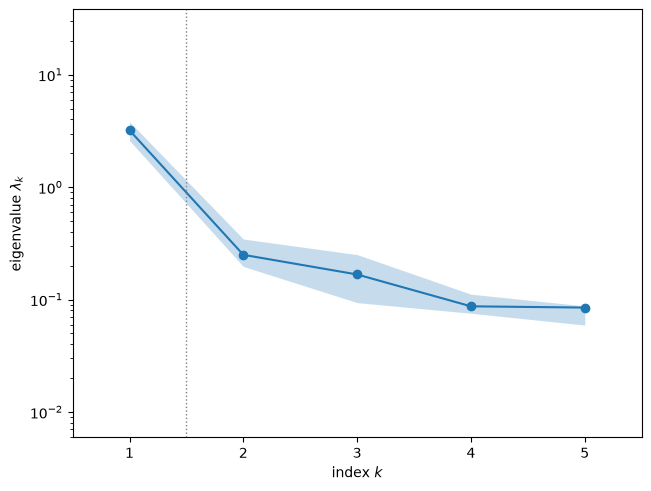

In [14]:
sub10 = subs10['NSE']
fig, ax = ac.plotting.plot_eigenvalues(sub10)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..4:', np.array2string(sub10.bootstrap_distances.mean(axis=0), precision=3))
fig

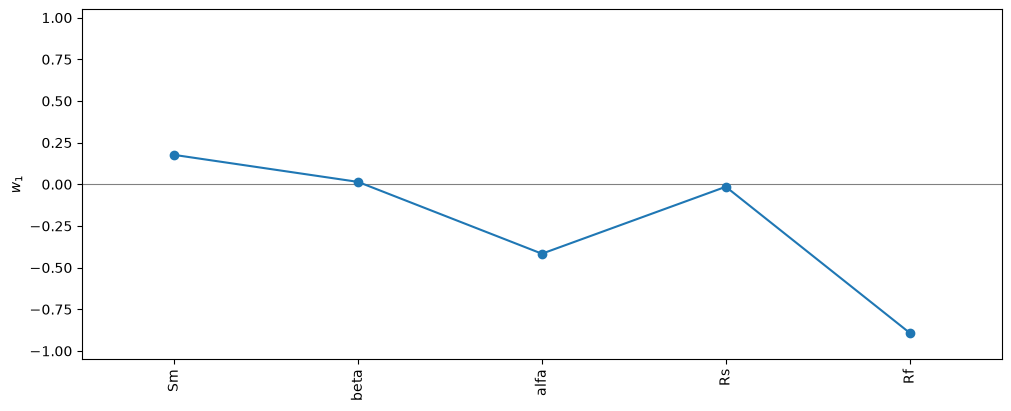

In [15]:
fig, axes = ac.plotting.plot_eigenvectors(sub10, indices=[0], labels=labels, figsize=(10, 4))
plt.close(fig)
fig

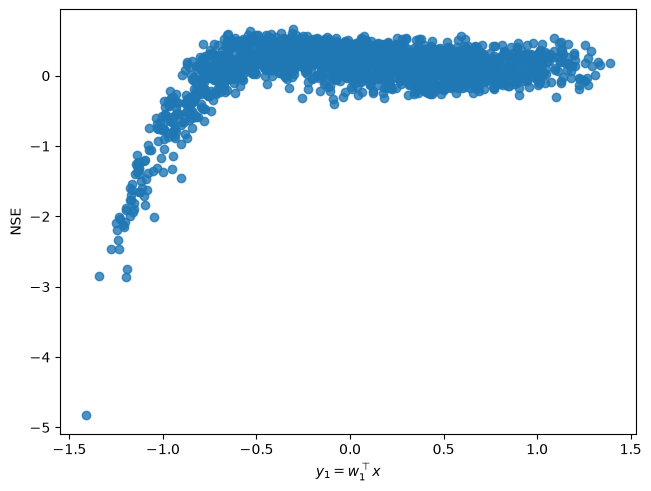

In [16]:
fig, ax = ac.plotting.plot_sufficient_summary(sub10, X=X10, f=f10[:, 0], dims=1, qoi_label='NSE')
plt.close(fig)
fig

On $S_m \in [10, 400]$ mm (1957 samples) the gap rule picks $n = 1$ for all three QoIs. For the NSE, $\lambda_1 = 3.204$ and $\lambda_1/\lambda_2 = 12.81$, the bootstrap mean distance for $k = 1$ is 0.024, and $\mathbf w_1$ = ($R_f$ $-0.892$, alfa $-0.416$, $S_m$ +0.177; beta and $R_s$ at most 0.015 in magnitude). This direction lies in the two-dimensional full-range subspace (projection norm 1.000). The NSE drops steeply at the left of the summary plot, where $R_f$ and alfa are large: too much rain is routed quickly, and the simulated peaks are too high. To the right is a plateau with a spread of the order of its height, which no function of $y_1$ can remove; this spread limits the surrogate below.

### A gradient-free cross-check

The kinks make one ask whether the almost-everywhere gradients describe the global trend. We re-estimate the subspaces from the QoI values alone, with local linear models fitted to nearest neighbours (`ac.local_linear_gradients`, the library's default neighbourhood), and compare the first eigenvectors.

In [17]:
print(f"{'QoI':6s} {'ranges':10s} {'LL l1/l2':>8s}  |w1(LL) . w1(grad)|  w1(LL)")
for k, q in enumerate(hm.QOI_NAMES):
    for tag, sp, XX, ff, s in (('full', space, X, f[:, k], subs[q]), ('Sm >= 10', space10, X10, f10[:, k], subs10[q])):
        ll = ac.local_linear_gradients(X=XX, f=ff, space=sp)
        sl = ac.active_subspace(space=sp, grads=ll)
        lam = sl.eigenvalues
        print(f'{q:6s} {tag:10s} {lam[0] / lam[1]:8.2f}  {abs(sl.W[:, 0] @ s.W[:, 0]):18.3f}  '
              f'{np.array2string(sl.W[:, 0] * np.sign(sl.W[:, 0] @ s.W[:, 0]), precision=3, suppress_small=True)}')

QoI    ranges     LL l1/l2  |w1(LL) . w1(grad)|  w1(LL)


NSE    full           5.76               0.693  [ 0.229  0.017 -0.487 -0.018 -0.843]


NSE    Sm >= 10       4.68               0.996  [ 0.184  0.034 -0.493 -0.013 -0.85 ]


Qmean  full           2.06               0.551  [-0.477  0.203  0.21   0.829 -0.01 ]


Qmean  Sm >= 10       2.46               0.930  [-0.348  0.214  0.191  0.892 -0.003]


Qmax   full          14.47               1.000  [-0.073 -0.048  0.47   0.065  0.876]


Qmax   Sm >= 10      13.61               0.999  [-0.07  -0.052  0.475  0.068  0.873]


For the NSE on the full ranges, the local-linear $\mathbf w_1$ ($R_f$ $-0.843$, alfa $-0.487$, $S_m$ +0.229) is close to the gradient-based $\mathbf w_1$ on $S_m \ge 10$ mm and not to the full-range one ($|\mathbf w_1\cdot\mathbf w_1| = 0.693$). The local fits use neighbourhoods of finite size and so cannot resolve the steep $S_m$ edge, which only 43 samples cover. On $S_m \ge 10$ mm the two estimates agree (0.996). For the peak flow they agree on both sets (1.000 and 0.999). For the mean flow they disagree on the full ranges (0.551) and partly on $S_m \ge 10$ mm (0.930), where the local-linear $\mathbf w_1$ gives more weight to $S_m$ ($-0.348$) and beta (0.214). For the NSE the local-linear $\lambda_1/\lambda_2$ is larger than the gradient-based one on the full ranges (5.76 against 1.79), as expected if the local fits miss the $S_m$ edge that makes $\lambda_2$ large there, and smaller on $S_m \ge 10$ mm (4.68 against 12.81).

### Peak and mean flow

Qmax (full): w1 Sm -0.072, beta -0.035, alfa +0.452, Rs +0.055, Rf +0.887
Qmax (Sm >= 10): w1 Sm -0.058, beta -0.036, alfa +0.451, Rs +0.055, Rf +0.888
Qmean (full): w1 Sm -0.996, beta +0.017, alfa +0.015, Rs +0.084, Rf +0.002
Qmean (Sm >= 10): w1 Sm -0.049, beta +0.037, alfa +0.092, Rs +0.994, Rf +0.003
Qmean (Sm >= 10): w2 Sm -0.939, beta +0.334, alfa +0.042, Rs -0.063, Rf +0.022


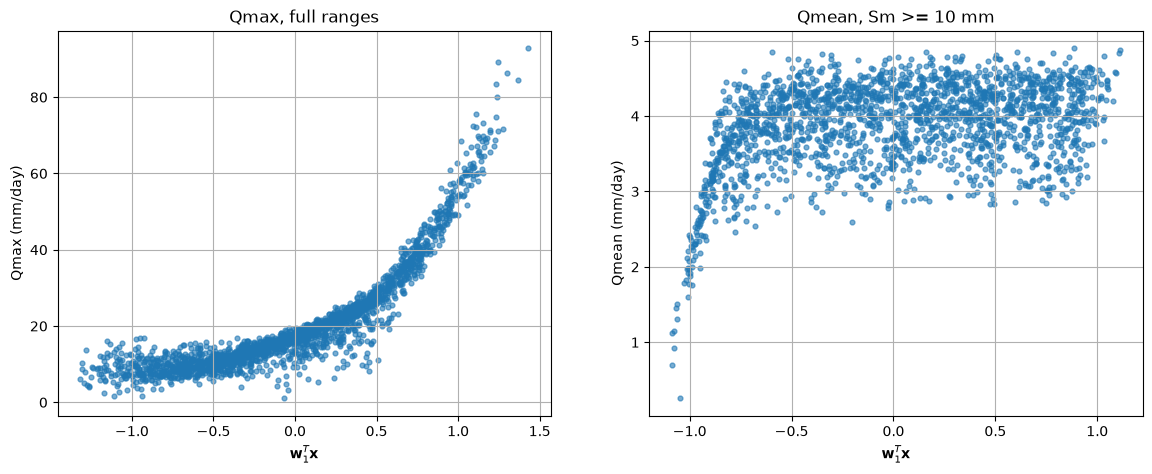

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, q, s, XX, ff in ((axes[0], 'Qmax', subs['Qmax'], X, f[:, 2]), (axes[1], 'Qmean', subs10['Qmean'], X10, f10[:, 1])):
    sp = space if q == 'Qmax' else space10
    y = sp.to_normalized(XX) @ s.W[:, 0]
    ax.scatter(y, ff, s=12, c='C0', alpha=0.6)
    ax.set_xlabel(r'$\mathbf{w}_1^T\mathbf{x}$')
    ax.set_ylabel(f'{q} (mm/day)')
    ax.set_title(f'{q}, ' + ('full ranges' if q == 'Qmax' else 'Sm >= 10 mm'))
    ax.grid(True)
plt.close(fig)
for q in ('Qmax', 'Qmean'):
    for tag, s in (('full', subs[q]), ('Sm >= 10', subs10[q])):
        print(f'{q} ({tag}): w1 ' + ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, s.W[:, 0])))
print('Qmean (Sm >= 10): w2 ' + ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, subs10['Qmean'].W[:, 1])))
fig

The peak flow increases along $\mathbf w_1$ = ($R_f$ +0.887, alfa +0.452), with $S_m$ ($-0.072$), beta and $R_s$ weights of at most 0.072 in magnitude, and the summary plot shows a tight convex trend: more of the excess rain through the quick cascade, released faster, gives higher peaks. On $S_m \ge 10$ mm the mean flow increases along $\mathbf w_1 \approx R_s$ (+0.994): with $R_s$ near 0 the slow store keeps its share $(1-\text{alfa})$ of the excess rain through the year, which gives the steep left edge of the plot. Away from that edge the mean flow spreads over about 2 mm/day at fixed $y_1$. That spread follows $\mathbf w_2$, which is mostly $S_m$ ($-0.939$) and beta (+0.334): the soil store controls how much water evaporates. The steep $R_s$ edge is partly a start-up transient: the slow store starts empty, and the 30-day warm-up is short against its time constant $1/R_s$ (10 days at $R_s = 0.1$/day, unbounded as $R_s \to 0$), so how much the slow store releases in the scored days depends on how far it has filled from that start. With a one-year spin-up (robustness section below) the full-range $\mathbf w_1$ of the mean flow moves from $S_m$ to $R_s$ ($R_s$ +0.994; $|\mathbf w_1\cdot\mathbf w_1^{\text{headline}}| = 0.185$).

### Surrogates on the active variables

We fit polynomials in the first one or two active variables and report the leave-one-out $R^2$.

NSE        1-D, degree 2/3/4: LOO R^2 0.430 / 0.727 / 0.786
NSE        2-D, degree 2/3/4: LOO R^2 0.460 / 0.778 / 0.838
NSE (full) 1-D, degree 2/3/4: LOO R^2 0.162 / 0.232 / 0.277
NSE (full) 2-D, degree 2/3/4: LOO R^2 0.447 / 0.762 / 0.825
Qmax       1-D, degree 2/3/4: LOO R^2 0.929 / 0.952 / 0.953


Qmax       2-D, degree 2/3/4: LOO R^2 0.957 / 0.977 / 0.982
Qmean      1-D, degree 2/3/4: LOO R^2 0.241 / 0.346 / 0.380
Qmean      2-D, degree 2/3/4: LOO R^2 0.601 / 0.686 / 0.731


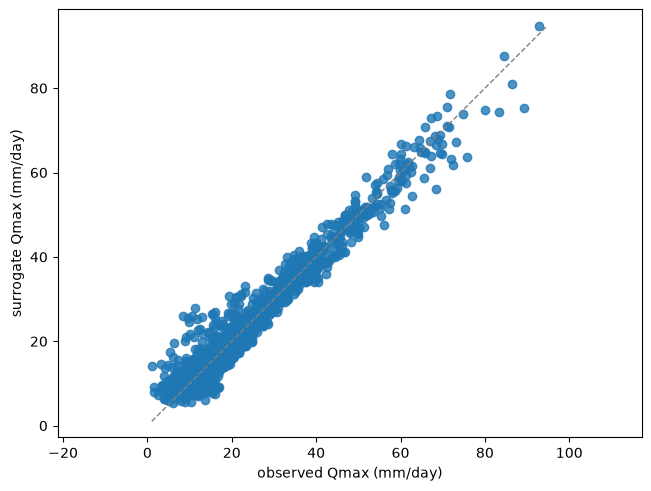

In [19]:
fits = {}
for q, k, s, XX, ff, sp in (('NSE', 0, sub10, X10, f10[:, 0], space10), ('NSE (full)', 0, subs['NSE'], X, f[:, 0], space),
                            ('Qmax', 2, subs['Qmax'], X, f[:, 2], space), ('Qmean', 1, subs10['Qmean'], X10, f10[:, 1], space10)):
    for dim in (1, 2):
        sd = ac.with_dimension(s, dim)
        r2 = [ac.fit_surrogate(X=XX, f=ff, space=sp, subspace=sd, kind='poly', degree=d).loo_r_squared for d in (2, 3, 4)]
        fits[(q, dim)] = r2
        print(f'{q:10s} {dim}-D, degree 2/3/4: LOO R^2 ' + ' / '.join(f'{v:.3f}' for v in r2))
sur = ac.fit_surrogate(X=X, f=f[:, 2], space=space, subspace=ac.with_dimension(subs['Qmax'], 1), kind='poly', degree=3)
fig, ax = ac.plotting.plot_surrogate_fit(sur, X=X, f=f[:, 2], qoi_label='Qmax (mm/day)')
plt.close(fig)
fig

For the peak flow, a cubic in $y_1$ has leave-one-out $R^2 = 0.952$ (0.977 for a cubic in two active variables; the figure shows the one-variable cubic). For the NSE on $S_m \ge 10$ mm, a quartic in $y_1$ reaches 0.786 and a quartic in $(y_1, y_2)$ 0.838. On the full ranges the one-variable quartic reaches only 0.277 and the two-variable quartic 0.825, which agrees with $n = 2$ there. For the mean flow, one-variable fits reach at most 0.380 and two-variable fits 0.731.

### Robustness: spin-up and other water years

The paper's setting starts every store empty on day 1 and scores days 31–365 of the first year of the record. To see how much the results depend on that choice, the next cell recomputes the QoIs and their gradients at the same 2000 samples, changing only the forcing, the scored window or the initial state: (a) no warm-up (days 1–365 scored; see the note on the paper's Fig. 4 under "The model"), (b) a one-year spin-up (the first year run twice, scored on days 31–365 of the second pass, so the stores start where the first year left them), and (c) three other water years (1 Oct–30 Sep) of the same record, 1950, 1951 and 1959 (`forcing_other_years.csv`, rows 366–730, 731–1095 and 3653–4017 of `LeafCatch.txt`), each with the 30-day warm-up and empty start. It prints the eigenvalue ratios, the gap-rule $n$, $\mathbf w_1$, and $|\mathbf w_1\cdot\mathbf w_1^{\text{headline}}|$ for each QoI on both input boxes (no bootstrap; the eigenpairs need none).

In [20]:
F2 = np.loadtxt('forcing_other_years.csv', delimiter=',')        # LeafCatch row, water year, rain, PET, flow (mm/day)
settings = {'WY1949 empty start (headline)': ((rain, pet, flow), hm.WARMUP),
            'WY1949 no warm-up': ((rain, pet, flow), 0),
            'WY1949 1-yr spin-up': ((np.r_[rain, rain], np.r_[pet, pet], np.r_[flow, flow]), 365 + hm.WARMUP)}
for y in np.unique(F2[:, 1]).astype(int):
    d = F2[F2[:, 1] == y]
    settings[f'WY{y} empty start'] = ((d[:, 2], d[:, 3], d[:, 4]), hm.WARMUP)

boxes = (('full', space, np.ones(len(X), bool)), ('Sm >= 10', space10, X[:, 0] >= SM_MIN))
rob = {}
for tag, (forc, wu) in settings.items():
    fr, Gr = hm.qoi_and_grad(X, forc, warmup=wu)
    print(f'{tag:30s}: scored rain {forc[0][wu:].sum():5.0f} mm, mean observed flow {forc[2][wu:].mean():.3f} mm/day, '
          f'median NSE {np.median(fr[:, 0]):.3f}')
    for k, q in enumerate(hm.QOI_NAMES):
        for btag, sp, keep in boxes:
            s = ac.orient(ac.active_subspace(space=sp, X=X[keep], f=fr[keep, k], grads=Gr[keep, k]),
                          by='covariance', X=X[keep], f=fr[keep, k], columns=1)
            rob[(tag, q, btag)] = s
head = list(settings)[0]
for k, q in enumerate(hm.QOI_NAMES):
    for btag, _, _ in boxes:
        print(f"\n{q}, {btag} ranges\n{'setting':30s} {'n':>2s} {'l1/l2':>6s} {'l2/l3':>6s}  {'|w1.w1h|':>8s}  w1 ({', '.join(names)})")
        for tag in settings:
            s = rob[(tag, q, btag)]
            lam = s.eigenvalues
            print(f'{tag:30s} {s.n:2d} {lam[0] / lam[1]:6.2f} {lam[1] / lam[2]:6.2f}  '
                  f'{abs(s.W[:, 0] @ rob[(head, q, btag)].W[:, 0]):8.3f}  '
                  f'{np.array2string(s.W[:, 0], precision=3, suppress_small=True)}')

WY1949 empty start (headline) : scored rain  2014 mm, mean observed flow 2.818 mm/day, median NSE 0.165


WY1949 no warm-up             : scored rain  2057 mm, mean observed flow 2.619 mm/day, median NSE 0.190


WY1949 1-yr spin-up           : scored rain  2014 mm, mean observed flow 2.818 mm/day, median NSE 0.187


WY1950 empty start            : scored rain  1484 mm, mean observed flow 1.916 mm/day, median NSE 0.270


WY1951 empty start            : scored rain  1154 mm, mean observed flow 1.160 mm/day, median NSE 0.350


WY1959 empty start            : scored rain  1143 mm, mean observed flow 0.999 mm/day, median NSE -0.537

NSE, full ranges
setting                         n  l1/l2  l2/l3  |w1.w1h|  w1 (Sm, beta, alfa, Rs, Rf)
WY1949 empty start (headline)   2   1.79  15.62     1.000  [ 0.86   0.006 -0.237 -0.01  -0.451]
WY1949 no warm-up               2   1.84  15.69     1.000  [ 0.868  0.005 -0.232 -0.01  -0.438]
WY1949 1-yr spin-up             2   1.64   4.51     0.998  [ 0.831  0.015 -0.253 -0.011 -0.494]
WY1950 empty start              1   2.19   7.19     0.976  [-0.95  -0.014  0.173  0.008  0.261]
WY1951 empty start              1   4.70  16.80     0.935  [ 0.985 -0.    -0.094 -0.006 -0.146]
WY1959 empty start              1  15.82   7.49     0.907  [ 0.995 -0.001 -0.057 -0.009 -0.083]

NSE, Sm >= 10 ranges
setting                         n  l1/l2  l2/l3  |w1.w1h|  w1 (Sm, beta, alfa, Rs, Rf)
WY1949 empty start (headline)   1  12.81   1.50     1.000  [ 0.177  0.015 -0.416 -0.015 -0.892]
WY1949 no

**Robustness results.** Scoring all 365 days (no warm-up) changes little: for the NSE, $\lambda_1/\lambda_2$ is 12.01 on $S_m \ge 10$ mm (12.81 in the paper's setting) and 1.84 on the full ranges, still with $n = 2$; the peak flow is unchanged (18.19). So the open question of the 2015 warm-up does not affect the headline. The start and the year matter more: the strength of the structure depends on them, while the directions mostly do not. For the NSE on $S_m \ge 10$ mm the gap rule picks $n = 1$ in every setting, and $\mathbf w_1$ stays an $R_f$–alfa direction ($|\mathbf w_1\cdot\mathbf w_1^{\text{headline}}|$ = 0.999, 0.997 and 0.984 for the spin-up, 1950 and 1951; 0.833 in 1959, where the weight of $S_m$ grows to 0.684), but $\lambda_1/\lambda_2$ is 5.31 with the spin-up and 5.62, 5.43 and 3.26 in the other years, against 12.81 in the paper's setting. On the full ranges the spin-up keeps $n = 2$ ($\lambda_1/\lambda_2 = 1.64$, $\lambda_2/\lambda_3 = 4.51$ against 15.62), while in the three other years the gap rule picks $n = 1$, with $\mathbf w_1$ mostly $S_m$ (weights 0.950–0.995 in magnitude; $\lambda_1/\lambda_2$ = 2.19, 4.70 and 15.82): the full-range $n = 2$ is particular to the first year. For the mean flow on the full ranges the spin-up swaps the first two directions ($\mathbf w_1$ becomes $R_s$, +0.994; $|\mathbf w_1\cdot\mathbf w_1^{\text{headline}}| = 0.185$, $\lambda_1/\lambda_2 = 1.29$); on $S_m \ge 10$ mm, $\mathbf w_1 \approx R_s$ in every setting, with $\lambda_1/\lambda_2$ from 1.94 to 26.64. The peak flow keeps its $R_f$–alfa direction with the spin-up and in 1950 and 1951 ($|\mathbf w_1\cdot\mathbf w_1^{\text{headline}}| \ge 0.991$; $\lambda_1/\lambda_2$ = 17.06, 15.48 and 7.28), but in 1959, the driest of the windows (1143 mm of rain in the scored days against 2014 mm), $S_m$ enters $\mathbf w_1$ ($-0.577$) and $\lambda_1/\lambda_2$ falls to 2.02. The rest of the notebook keeps the paper's setting.

### Comparison with the paper

The paper reports no active subspace. Its Fig. 3a gives the Elementary Effects Test (EET, the method of Morris [[6]](https://doi.org/10.1080/00401706.1991.10484804)) for the NSE: the mean of the absolute elementary effects and their standard deviation, from $r = 100$ radial one-at-a-time designs with Latin hypercube base points (600 model runs, Fig. 4), with bootstrap bounds. An elementary effect of input $j$ is a finite-difference slope in units of the input range, $\mathrm{EE}_j = \frac{f(\mathbf p + \Delta_j\mathbf e_j) - f(\mathbf p)}{\Delta_j}\,(\text{upper}_j - \text{lower}_j)$. We compute the same indices with our model and our own radial design (Campolongo et al. [[5]](https://doi.org/10.1016/j.cpc.2010.12.039): base and auxiliary points from one Latin hypercube in $2m$ dimensions, seeded with `SEED`), for $r = 100$ with 1000 bootstrap resamples and for $r = 2000$. The infinitesimal version is $\mathbb E\,|\partial f/\partial p_j|\,(\text{upper}_j - \text{lower}_j)$, which the gradient data give directly, and the activity score $\sum_{i \le n} \lambda_i w_{ij}^2$ of the active subspace is its squared counterpart.

In [21]:
def radial_ee(r, seed):
    U = qmc.LatinHypercube(d=10, seed=seed).random(r)
    base = hm.LOWER + (hm.UPPER - hm.LOWER) * U[:, :5]
    aux = hm.LOWER + (hm.UPPER - hm.LOWER) * U[:, 5:]
    pts = [base] + [np.where(np.arange(5) == j, aux, base) for j in range(5)]
    Y = hm.qoi(np.vstack(pts))[:, 0].reshape(6, r)          # NSE
    return (Y[1:] - Y[0]).T / (aux - base) * (hm.UPPER - hm.LOWER)   # (r, 5)


rng = np.random.default_rng(SEED)
EE100 = radial_ee(100, rng)
EE2000 = radial_ee(2000, rng)
B = rng.integers(0, 100, size=(1000, 100))
mi_b = np.abs(EE100[B]).mean(axis=1)
sd_b = EE100[B].std(axis=1)
Gu = G[:, 0] * (hm.UPPER - hm.LOWER)                         # d NSE / d(input in units of its range)
act = np.sum(sub.eigenvalues[:sub.n] * sub.W[:, :sub.n] ** 2, axis=1)
act10 = np.sum(sub10.eigenvalues[:sub10.n] * sub10.W[:, :sub10.n] ** 2, axis=1)
paper_mi = {'Sm': 0.24, 'beta': 0.15, 'alfa': 0.90, 'Rs': 0.30, 'Rf': 1.10}   # read from Fig. 3a
paper_sd = {'Sm': 0.31, 'beta': 0.19, 'alfa': 1.09, 'Rs': 0.32, 'Rf': 2.05}
print(f"{'input':5s} {'paper mean|EE|':>14s} {'r=100 [95% boot]':>20s} {'r=2000':>7s} {'E|df/du|':>9s} | "
      f"{'paper sd(EE)':>12s} {'r=100 [95% boot]':>20s} {'r=2000':>7s} {'sd df/du':>9s} | {'activity':>8s} {'act. Sm>=10':>11s}")
for j, n in enumerate(names):
    lo_m, hi_m = np.percentile(mi_b[:, j], [2.5, 97.5])
    lo_s, hi_s = np.percentile(sd_b[:, j], [2.5, 97.5])
    print(f'{n:5s} {paper_mi[n]:14.2f} {np.abs(EE100[:, j]).mean():6.2f} [{lo_m:4.2f}, {hi_m:4.2f}] {np.abs(EE2000[:, j]).mean():7.2f} '
          f'{np.abs(Gu[:, j]).mean():9.2f} | {paper_sd[n]:12.2f} {EE100[:, j].std():6.2f} [{lo_s:4.2f}, {hi_s:4.2f}] '
          f'{EE2000[:, j].std():7.2f} {Gu[:, j].std():9.2f} | {act[j]:8.3f} {act10[j]:11.3f}')
inside = [n for j, n in enumerate(names) if np.percentile(mi_b[:, j], 2.5) <= paper_mi[n] <= np.percentile(mi_b[:, j], 97.5)]
inside_sd = [n for j, n in enumerate(names) if np.percentile(sd_b[:, j], 2.5) <= paper_sd[n] <= np.percentile(sd_b[:, j], 97.5)]
print(f'paper value inside the r = 100 bootstrap interval: mean|EE| {inside}; sd(EE) {inside_sd}')
rank = lambda v: ' > '.join(names[j] for j in np.argsort(-np.asarray(v)))
print('\nranking, paper Fig. 3a mean|EE|:', rank([paper_mi[n] for n in names]))
print('ranking, r = 2000 mean|EE|:      ', rank(np.abs(EE2000).mean(axis=0)))
print('ranking, E|df/du|:               ', rank(np.abs(Gu).mean(axis=0)))
print('ranking, activity score (full):  ', rank(act))
print('ranking, activity score (Sm>=10):', rank(act10))

input paper mean|EE|     r=100 [95% boot]  r=2000  E|df/du| | paper sd(EE)     r=100 [95% boot]  r=2000  sd df/du | activity act. Sm>=10
Sm              0.24   0.19 [0.14, 0.25]    0.33      0.86 |         0.31   0.30 [0.22, 0.38]    0.93      4.04 |    4.220       0.100
beta            0.15   0.24 [0.17, 0.36]    0.22      0.29 |         0.19   0.56 [0.19, 0.89]    0.42      0.59 |    0.001       0.001
alfa            0.90   0.83 [0.66, 1.02]    0.86      0.99 |         1.09   1.02 [0.78, 1.24]    1.18      1.45 |    0.583       0.556
Rs              0.30   0.32 [0.20, 0.52]    0.24      0.31 |         0.32   0.97 [0.21, 1.63]    0.36      0.77 |    0.001       0.001
Rf              1.10   0.81 [0.58, 1.10]    0.91      1.43 |         2.05   1.49 [0.87, 2.11]    1.81      3.15 |    2.627       2.547
paper value inside the r = 100 bootstrap interval: mean|EE| ['Sm', 'alfa', 'Rs']; sd(EE) ['Sm', 'alfa', 'Rs', 'Rf']

ranking, paper Fig. 3a mean|EE|: Rf > alfa > Rs > Sm > beta
ranking, r 

| Quantity | Paper value | Notebook value |
|---|---|---|
| Inputs and ranges | 5 uniform, Fig. 4 | the same |
| Catchment, period, warm-up | not stated; Fig. 4 excerpts a version of SAFE-matlab's `workflow_eet_hymod.m`, whose current Step 2 uses `LeafCatch(1:365,:)`, `warmup = 30`, stores empty at day 1 (the excerpt's Step 4 has no warm-up argument) | the same: Leaf River, days 1–365, days 31–365 scored, empty start |
| EET design | $r = 100$ radial, Latin hypercube, 600 runs (Fig. 4) | $r = 100$ (600 runs) and $r = 2000$ (12 000 runs), own radial design |
| mean $\lvert\mathrm{EE}\rvert$: $R_f$, alfa, $R_s$, $S_m$, beta | 1.10, 0.90, 0.30, 0.24, 0.15 (Fig. 3a, read) | $r = 100$: 0.81, 0.83, 0.32, 0.19, 0.24; $r = 2000$: 0.91, 0.86, 0.24, 0.33, 0.22 |
| sd(EE): $R_f$, alfa, $R_s$, $S_m$, beta | 2.05, 1.09, 0.32, 0.31, 0.19 (Fig. 3a, read) | $r = 100$: 1.49, 1.02, 0.97, 0.30, 0.56; $r = 2000$: 1.81, 1.18, 0.36, 0.93, 0.42 |
| Ranking by mean $\lvert\mathrm{EE}\rvert$ | $R_f$ > alfa > $R_s$ > $S_m$ > beta | $r = 2000$: $R_f$ > alfa > $S_m$ > $R_s$ > beta |
| Active subspace of the NSE (days 1–365, empty start) | not reported | full ranges: $n = 2$, $\lambda_1/\lambda_2 = 1.79$, $\lambda_2/\lambda_3 = 15.62$; $S_m \ge 10$ mm: $n = 1$, $\lambda_1/\lambda_2 = 12.81$, $\mathbf w_1$ = ($R_f$ $-0.892$, alfa $-0.416$, $S_m$ +0.177) |
| Active subspace of the peak flow (days 1–365, empty start) | not reported | $n = 1$, $\lambda_1/\lambda_2 = 18.19$, LOO $R^2$ = 0.952 (cubic) |
| NSE $\lambda_1/\lambda_2$ on $S_m \ge 10$ mm, other settings | not reported | no warm-up 12.01; 1-yr spin-up 5.31; water years 1950, 1951, 1959: 5.62, 5.43, 3.26 ($\mathbf w_1$ still mainly $R_f$ and alfa) |
| Peak flow $\lambda_1/\lambda_2$, other settings | not reported | no warm-up 18.19; 1-yr spin-up 17.06; water years 1950, 1951, 1959: 15.48, 7.28, 2.02 |

The paper's values are read from Fig. 3a to about $\pm0.02$. Our $r = 100$ bootstrap intervals contain the paper's mean $|\mathrm{EE}|$ for $S_m$, alfa and $R_s$ and its sd(EE) for $S_m$, alfa, $R_s$ and $R_f$; the paper's mean for $R_f$ (1.10) and sd for beta (0.19) sit at the ends of our intervals ([0.58, 1.10] and [0.19, 0.89]), and its mean for beta (0.15) is below ours ([0.17, 0.36]). With intervals this wide, a 600-run EET separates $R_f$ and alfa from the other three inputs but cannot order $R_s$, $S_m$ and beta, and $R_s$ and $S_m$ swap places between the paper and our $r = 2000$ run. Every estimate puts $R_f$ and alfa first, as the restricted active subspace does. The full-range activity scores instead rank $S_m$ first (4.220 against 2.627 for $R_f$): they are second moments of the gradient and so weight the rare, large gradients near $S_m = 0$, whereas $|\mathrm{EE}|$ is a first moment of finite-difference slopes taken over steps that are mostly much wider than the steep edge. On $S_m \ge 10$ mm the activity scores give the same order as the $r = 2000$ EET and as $\mathbb E|\partial f/\partial u|$: $R_f$ > alfa > $S_m$ > $R_s$ > beta.

### References

[1] F. Pianosi, F. Sarrazin, and T. Wagener. [A Matlab toolbox for Global Sensitivity Analysis](https://doi.org/10.1016/j.envsoft.2015.04.009). *Environmental Modelling & Software*, 70:80–85, 2015.

[2] T. Wagener, D. P. Boyle, M. J. Lees, H. S. Wheater, H. V. Gupta, and S. Sorooshian. [A framework for development and application of hydrological models](https://doi.org/10.5194/hess-5-13-2001). *Hydrology and Earth System Sciences*, 5(1):13–26, 2001. HyMod was introduced in D. P. Boyle, *Multicriteria calibration of hydrological models*, PhD thesis, University of Arizona, Tucson, 2001 (not read for this notebook).

[3] S. Sorooshian, V. K. Gupta, and J. L. Fulton. [Evaluation of maximum likelihood parameter estimation techniques for conceptual rainfall-runoff models: Influence of calibration data variability and length on model credibility](https://doi.org/10.1029/WR019i001p00251). *Water Resources Research*, 19(1):251–259, 1983.

[4] J. B. Kollat, P. M. Reed, and T. Wagener. [When are multiobjective calibration trade-offs in hydrologic models meaningful?](https://doi.org/10.1029/2011WR011534) *Water Resources Research*, 48(3), 2012. (Not read for this notebook; cited because SAFE's workflow scripts attribute the parameter ranges to it.)

[5] F. Campolongo, A. Saltelli, and J. Cariboni. [From screening to quantitative sensitivity analysis. A unified approach](https://doi.org/10.1016/j.cpc.2010.12.039). *Computer Physics Communications*, 182(4):978–988, 2011.

[6] M. D. Morris. [Factorial sampling plans for preliminary computational experiments](https://doi.org/10.1080/00401706.1991.10484804). *Technometrics*, 33(2):161–174, 1991.

[7] J. E. Nash and J. V. Sutcliffe. [River flow forecasting through conceptual models part I — A discussion of principles](https://doi.org/10.1016/0022-1694(70)90255-6). *Journal of Hydrology*, 10(3):282–290, 1970.

[8] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, Philadelphia, 2015.

[9] F. Pianosi and F. Sarrazin. `workflow_eet_hymod.m`, SAFE-matlab, <https://github.com/SAFEtoolbox/SAFE-matlab> (GPL-3.0; script dated 2014, read at commit dc157e1 of 23 Feb 2026). The forcing window, warm-up and initial state used here are its Step 2 settings.

Code and data: SAFE-python, <https://github.com/SAFEtoolbox/SAFE-python>, and SAFE-matlab, <https://github.com/SAFEtoolbox/SAFE-matlab> (both GPL-3.0). HyMod is re-implemented here from reading SAFE's `hymod_sim` (no code or comments copied); the forcing data are from `LeafCatch.txt` (identical values in both repositories).

### Acknowledgments

From the paper: F. Pianosi and T. Wagener were supported by the Natural Environment Research Council [Consortium on Risk in the Environment: Diagnostics, Integration, Benchmarking, Learning and Elicitation (CREDIBLE); grant number NE/J017450/1]. F. Sarrazin was supported by a University of Bristol Alumni Postgraduate Scholarship.

In [22]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 67.9 s
